# MNIST Image Reconstruction and Generation: Autoencoder vs VAE


**Goal:** train a compact Convolutional Autoencoder (AE) and Variational Autoencoder (VAE), compare their reconstructions, and generate new digit-like images.

Submitted by

PRN : 202502110008

Name : Dhanashri Abhijit Shah

In [1]:
# If running in a fresh Colab/local environment, uncomment if needed:
# %pip install -q torch torchvision matplotlib pandas

import random, time, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 128
EPOCHS = 3
TRAIN_LIMIT = 10_000
TEST_LIMIT = 2_000
LATENT_DIM = 16
print("Device:", DEVICE)
print(f"Training images: {TRAIN_LIMIT:,} | Test images: {TEST_LIMIT:,} | Epochs/model: {EPOCHS}")

Device: cpu
Training images: 10,000 | Test images: 2,000 | Epochs/model: 3


## 1. Load and prepare MNIST

Pixel values are scaled to `[0, 1]`. A fixed subset is used to make training time predictable.

100%|██████████| 9.91M/9.91M [00:00<00:00, 65.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.63MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.5MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.68MB/s]


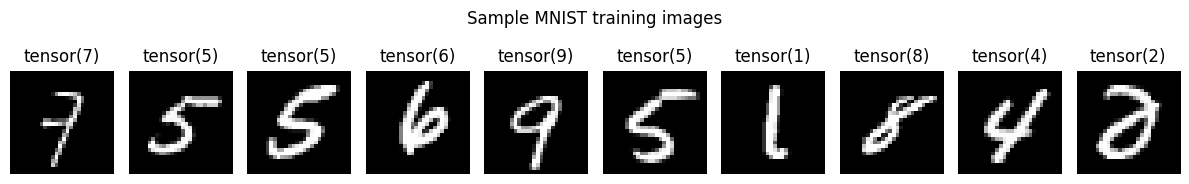

In [2]:
transform = transforms.ToTensor()
train_full = datasets.MNIST(root="./data", train=True, download=True, transform=transform)
test_full = datasets.MNIST(root="./data", train=False, download=True, transform=transform)

# Deterministic subsets
train_ds = Subset(train_full, range(TRAIN_LIMIT))
test_ds = Subset(test_full, range(TEST_LIMIT))
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=(DEVICE.type=="cuda"))
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=(DEVICE.type=="cuda"))

images, labels = next(iter(train_loader))
fig, axes = plt.subplots(1, 10, figsize=(12, 2))
for ax, img, label in zip(axes, images[:10], labels[:10]):
    ax.imshow(img.squeeze(), cmap="gray"); ax.set_title(str(label)); ax.axis("off")
plt.suptitle("Sample MNIST training images"); plt.tight_layout(); plt.show()

## 2. Build the Convolutional Autoencoder

The encoder compresses each 28×28 image into a 16-value latent vector. The decoder reconstructs the image from that vector. The AE is trained with pixel-wise Binary Cross-Entropy (BCE).

In [3]:
class ConvAutoencoder(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),  # 14x14
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(), # 7x7
            nn.Flatten(), nn.Linear(32*7*7, latent_dim)
        )
        self.decoder_input = nn.Linear(latent_dim, 32*7*7)
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (32, 7, 7)),
            nn.ConvTranspose2d(32, 16, 4, stride=2, padding=1), nn.ReLU(), # 14x14
            nn.ConvTranspose2d(16, 1, 4, stride=2, padding=1), nn.Sigmoid() # 28x28
        )
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(self.decoder_input(z))

ae = ConvAutoencoder().to(DEVICE)


## 3. Build the Variational Autoencoder (VAE)

The VAE encoder predicts a mean (`mu`) and log-variance (`logvar`) for a probability distribution. A latent vector is sampled using the reparameterization trick. Its loss combines reconstruction BCE and KL divergence, which encourages a smooth latent space useful for generation.

In [4]:
class ConvVAE(nn.Module):
    def __init__(self, latent_dim=LATENT_DIM):
        super().__init__()
        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Flatten()
        )
        self.fc_mu = nn.Linear(32*7*7, latent_dim)
        self.fc_logvar = nn.Linear(32*7*7, latent_dim)
        self.decoder_input = nn.Linear(latent_dim, 32*7*7)
        self.decoder = nn.Sequential(
            nn.Unflatten(1, (32, 7, 7)),
            nn.ConvTranspose2d(32, 16, 4, stride=2, padding=1), nn.ReLU(),
            nn.ConvTranspose2d(16, 1, 4, stride=2, padding=1), nn.Sigmoid()
        )
    def encode(self, x):
        h = self.encoder_conv(x)
        return self.fc_mu(h), self.fc_logvar(h)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std
    def decode(self, z):
        return self.decoder(self.decoder_input(z))
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar

vae = ConvVAE().to(DEVICE)

## 4. Train both models

Both models see the same training subset and number of epochs. The VAE objective is `BCE + KL`. KL is summed over latent dimensions and averaged over the batch; BCE is summed over pixels and averaged over the batch.

In [5]:
def train_autoencoder(model, loader, epochs):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train(); total = 0.0
        for x, _ in loader:
            x = x.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            recon = model(x)
            loss = nn.functional.binary_cross_entropy(recon, x, reduction="sum") / x.size(0)
            loss.backward(); optimizer.step()
            total += loss.item() * x.size(0)
        avg = total / len(loader.dataset); history.append(avg)
        print(f"AE | Epoch {epoch+1}/{epochs} | BCE: {avg:.2f}")
    return history, time.time()-start

def vae_loss(recon, x, mu, logvar):
    bce = nn.functional.binary_cross_entropy(recon, x, reduction="sum")
    # KL divergence from q(z|x) to standard normal N(0,I)
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return (bce + kld) / x.size(0), bce / x.size(0), kld / x.size(0)

def train_vae(model, loader, epochs):
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
    history = []
    start = time.time()
    for epoch in range(epochs):
        model.train(); total = 0.0; rec_total = 0.0; kl_total = 0.0
        for x, _ in loader:
            x = x.to(DEVICE)
            optimizer.zero_grad(set_to_none=True)
            recon, mu, logvar = model(x)
            loss, rec, kl = vae_loss(recon, x, mu, logvar)
            loss.backward(); optimizer.step()
            total += loss.item()*x.size(0); rec_total += rec.item()*x.size(0); kl_total += kl.item()*x.size(0)
        avg = total / len(loader.dataset); history.append(avg)
        print(f"VAE | Epoch {epoch+1}/{epochs} | Total: {avg:.2f} | BCE: {rec_total/len(loader.dataset):.2f} | KL: {kl_total/len(loader.dataset):.2f}")
    return history, time.time()-start

print("Training Autoencoder...")
ae_history, ae_seconds = train_autoencoder(ae, train_loader, EPOCHS)
print("\nTraining VAE...")
vae_history, vae_seconds = train_vae(vae, train_loader, EPOCHS)
print(f"\nTraining time — AE: {ae_seconds:.1f}s | VAE: {vae_seconds:.1f}s")

Training Autoencoder...
AE | Epoch 1/3 | BCE: 293.68
AE | Epoch 2/3 | BCE: 202.42
AE | Epoch 3/3 | BCE: 169.22

Training VAE...
VAE | Epoch 1/3 | Total: 320.47 | BCE: 301.03 | KL: 19.44
VAE | Epoch 2/3 | Total: 190.74 | BCE: 175.95 | KL: 14.78
VAE | Epoch 3/3 | Total: 162.04 | BCE: 143.71 | KL: 18.33

Training time — AE: 15.4s | VAE: 15.0s


## 5. Compare reconstruction quality

We use **test-set MSE** and **PSNR** as simple quantitative measures. Lower MSE and higher PSNR indicate closer pixel-level reconstruction. The side-by-side image grid is important too: metrics alone do not fully describe perceived image quality.

,Model,Test MSE,Test PSNR (dB),Training time (s)
0,Autoencoder,0.0397,14.0073,15.4401
1,VAE,0.0347,14.5988,14.9501


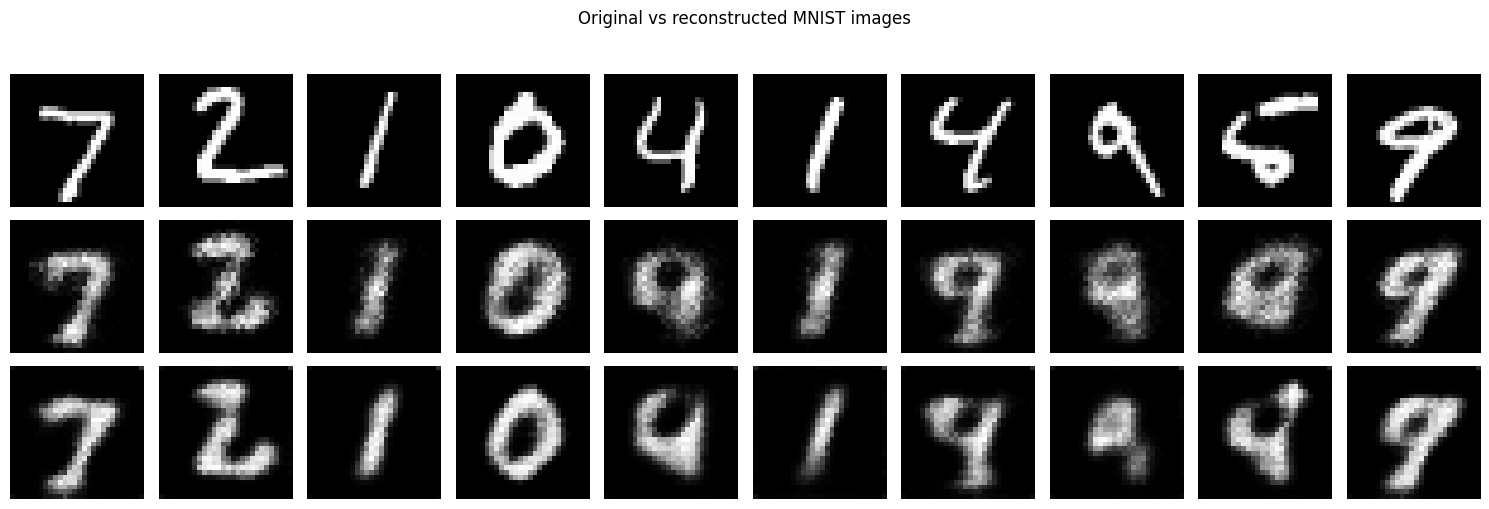

In [6]:
@torch.no_grad()
def collect_reconstructions(ae_model, vae_model, loader):
    ae_model.eval(); vae_model.eval()
    originals, ae_outputs, vae_outputs = [], [], []
    for x, _ in loader:
        x = x.to(DEVICE)
        ae_outputs.append(ae_model(x).cpu())
        vae_recon, _, _ = vae_model(x)
        vae_outputs.append(vae_recon.cpu())
        originals.append(x.cpu())
    return torch.cat(originals), torch.cat(ae_outputs), torch.cat(vae_outputs)

originals, ae_recons, vae_recons = collect_reconstructions(ae, vae, test_loader)

def image_metrics(target, prediction):
    mse = torch.mean((target-prediction)**2).item()
    psnr = 10 * math.log10(1.0 / max(mse, 1e-12))
    return mse, psnr

ae_mse, ae_psnr = image_metrics(originals, ae_recons)
vae_mse, vae_psnr = image_metrics(originals, vae_recons)

metrics = pd.DataFrame([
    {"Model":"Autoencoder", "Test MSE":ae_mse, "Test PSNR (dB)":ae_psnr, "Training time (s)":ae_seconds},
    {"Model":"VAE", "Test MSE":vae_mse, "Test PSNR (dB)":vae_psnr, "Training time (s)":vae_seconds}
])
display(metrics.round(4))

n = 10
fig, axes = plt.subplots(3, n, figsize=(15, 5))
for i in range(n):
    axes[0,i].imshow(originals[i,0], cmap="gray"); axes[0,i].axis("off")
    axes[1,i].imshow(ae_recons[i,0], cmap="gray"); axes[1,i].axis("off")
    axes[2,i].imshow(vae_recons[i,0], cmap="gray"); axes[2,i].axis("off")
axes[0,0].set_ylabel("Original", fontsize=10)
axes[1,0].set_ylabel("AE", fontsize=10)
axes[2,0].set_ylabel("VAE", fontsize=10)
plt.suptitle("Original vs reconstructed MNIST images", y=1.02)
plt.tight_layout(); plt.show()

## 6. Generate new images

The AE has no explicit prior distribution, so random latent vectors may not decode into meaningful digits. For a fair AE generation demonstration, we sample latent vectors from the AE's encoded training examples. The VAE is designed so that random samples from `N(0, I)` can be decoded into new digit-like images.

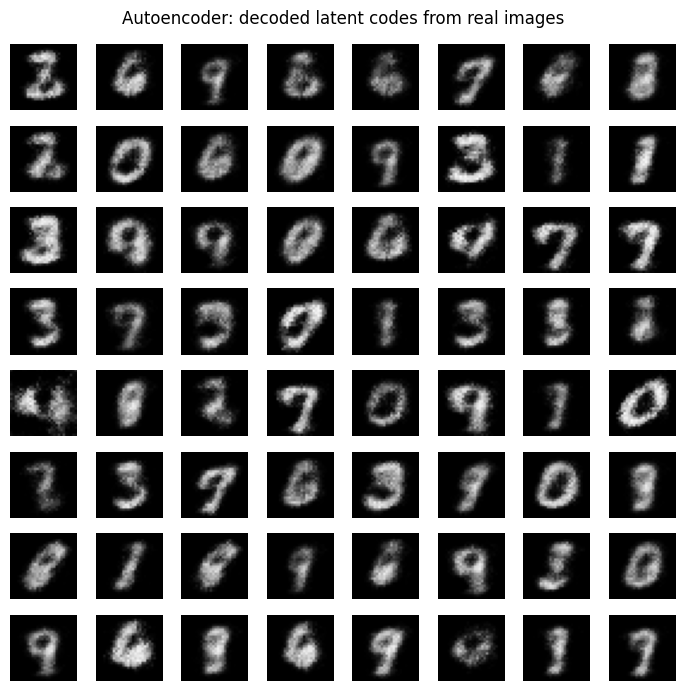

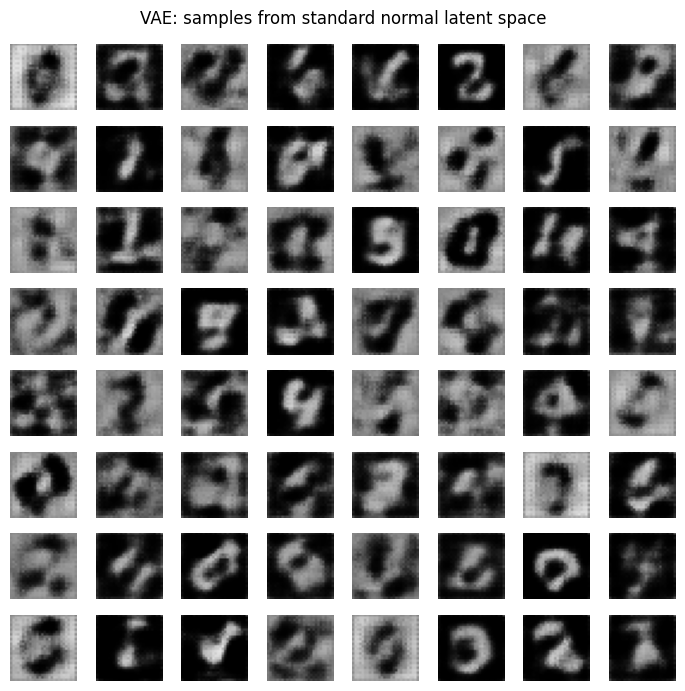

In [7]:
@torch.no_grad()
def show_image_grid(images, title, nrow=8):
    images = images.detach().cpu().clamp(0,1)
    n = min(len(images), nrow*nrow)
    fig, axes = plt.subplots(nrow, nrow, figsize=(7,7))
    for i, ax in enumerate(axes.flat):
        ax.axis("off")
        if i < n: ax.imshow(images[i,0], cmap="gray", vmin=0, vmax=1)
    plt.suptitle(title); plt.tight_layout(); plt.show()

# AE: encode real examples, then decode sampled latent codes
ae.eval(); vae.eval()
with torch.no_grad():
    seed_images, _ = next(iter(train_loader))
    seed_images = seed_images.to(DEVICE)
    ae_latents = ae.encoder(seed_images)
    chosen = ae_latents[torch.randperm(len(ae_latents), device=DEVICE)[:64]]
    ae_generated = ae.decoder(ae.decoder_input(chosen))

    # VAE: draw latent vectors from the standard normal prior
    z = torch.randn(64, LATENT_DIM, device=DEVICE)
    vae_generated = vae.decode(z)

show_image_grid(ae_generated, "Autoencoder: decoded latent codes from real images")
show_image_grid(vae_generated, "VAE: samples from standard normal latent space")

## 7. Latent-space interpolation (VAE)

A useful property of the VAE is that nearby latent points often decode to gradual changes. This cell interpolates between two random latent vectors.

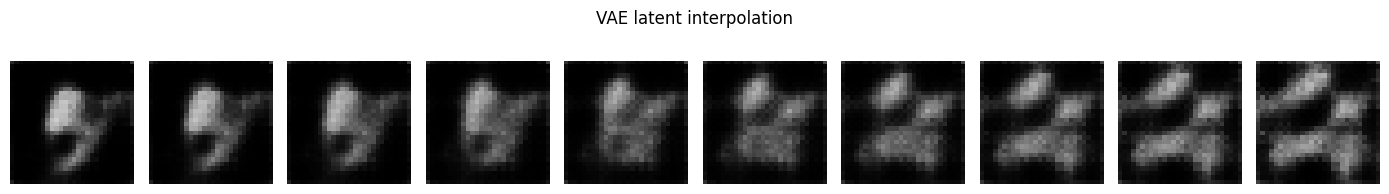

In [8]:
vae.eval()
with torch.no_grad():
    z1 = torch.randn(1, LATENT_DIM, device=DEVICE)
    z2 = torch.randn(1, LATENT_DIM, device=DEVICE)
    steps = torch.linspace(0, 1, 10, device=DEVICE).unsqueeze(1)
    z_path = (1-steps)*z1 + steps*z2
    interpolated = vae.decode(z_path)
fig, axes = plt.subplots(1, 10, figsize=(14, 2))
for ax, img in zip(axes, interpolated):
    ax.imshow(img.squeeze().cpu(), cmap="gray", vmin=0, vmax=1); ax.axis("off")
plt.suptitle("VAE latent interpolation"); plt.tight_layout(); plt.show()

## 8. Results and conclusion

Use the actual metric values and plots produced above in your report. Expected observations (verify against your run):

- **Autoencoder:** often gives sharper, lower-error reconstructions because it directly optimizes reconstruction. Its latent space is not constrained to follow a known distribution, so arbitrary random latent samples may be poor.
- **VAE:** often produces smoother or slightly blurrier reconstructions because its loss also regularizes the latent distribution. In return, sampling `z ~ N(0, I)` gives a principled way to generate new images, and interpolation is usually smoother.
- **Trade-off:** AE prioritizes faithful reconstruction; VAE prioritizes a structured, sampleable latent space and generative capability.

**Important:** exact scores depend on hardware, random seed, training subset, and epochs. Do not copy assumed values into your report; use the metrics from your own execution.